In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import median, mean

In [245]:
pok = pd.read_csv("pokazaniya.csv", sep=';', encoding='utf-8')
prib = pd.read_csv("pribory.csv", sep=';', encoding='utf-8')
sob = pd.read_csv("sobytiya.csv", sep=';', encoding='utf-8')

In [246]:
pok

,anon_id,data,pokazanie,paketov_za_sutki
0,6478032,2025-10-01,18.690000,1
1,6478032,2025-10-02,18.774000,1
2,6478032,2025-10-03,18.855000,1
3,6478032,2025-10-04,18.895000,1
4,6478032,2025-10-05,18.933000,1
...,...,...,...,...
693438,9096678,2026-09-21,46.943000,10
693439,9096678,2026-09-25,47.594364,9
693440,9096678,2026-09-26,47.734000,13
693441,9096678,2026-09-28,47.995000,1


In [247]:
pok.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693443 entries, 0 to 693442
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   anon_id           693443 non-null  int64  
 1   data              693443 non-null  object 
 2   pokazanie         693443 non-null  float64
 3   paketov_za_sutki  693443 non-null  int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 21.2+ MB


In [248]:
pok.data = pd.to_datetime(pok.data)                          # переводим формат даты в datetime
# pok.data.dtype
pok = pok.sort_values(["anon_id", "data"])                     # сортируем показания по id и дате
pok["prev_pok"] = pok.groupby("anon_id")["pokazanie"].shift(1) # находим предыдущее показание путем сдвига на 1 строку вниз
pok["sut_potreb"] = pok.pokazanie.values - pok.prev_pok.values # суточный расчет
pok

,anon_id,data,pokazanie,paketov_za_sutki,prev_pok,sut_potreb
440708,1001589,2025-10-01,280.760000,1,NaN,NaN
440709,1001589,2025-10-02,280.840000,1,280.760000,0.080000
440710,1001589,2025-10-03,280.864000,2,280.840000,0.024000
440711,1001589,2025-10-04,280.910000,1,280.864000,0.046000
440712,1001589,2025-10-05,281.130000,1,280.910000,0.220000
...,...,...,...,...,...,...
173986,9997690,2026-09-26,725.350000,19,724.443500,0.906500
173987,9997690,2026-09-27,726.116111,25,725.350000,0.766111
173988,9997690,2026-09-28,727.044353,25,726.116111,0.928242
173989,9997690,2026-09-29,727.723727,25,727.044353,0.679374


In [249]:
pok["prev_data"] = pok.groupby("anon_id")["data"].shift(1) # находим предыдущий день
pok["day_diff"] = (pok.data - pok.prev_data).dt.days       # разница в днях (норм - 1 день, аном > 1 дня), переводим в числовой формат
# print((pok.day_diff == 1).sum()) # 616414 из 693443 
mask_day_diff = pok.day_diff == 1.                         # маска для разницы дней = 1
pok_1_day = pok.loc[mask_day_diff, :].copy()               # оставляем только разницу в 1 день
len(pok_1_day)                  

616414

In [250]:
pok_1_day

,anon_id,data,pokazanie,paketov_za_sutki,prev_pok,sut_potreb,prev_data,day_diff
440709,1001589,2025-10-02,280.840000,1,280.760000,0.080000,2025-10-01,1.0
440710,1001589,2025-10-03,280.864000,2,280.840000,0.024000,2025-10-02,1.0
440711,1001589,2025-10-04,280.910000,1,280.864000,0.046000,2025-10-03,1.0
440712,1001589,2025-10-05,281.130000,1,280.910000,0.220000,2025-10-04,1.0
440713,1001589,2025-10-06,281.180000,1,281.130000,0.050000,2025-10-05,1.0
...,...,...,...,...,...,...,...,...
173986,9997690,2026-09-26,725.350000,19,724.443500,0.906500,2026-09-25,1.0
173987,9997690,2026-09-27,726.116111,25,725.350000,0.766111,2026-09-26,1.0
173988,9997690,2026-09-28,727.044353,25,726.116111,0.928242,2026-09-27,1.0
173989,9997690,2026-09-29,727.723727,25,727.044353,0.679374,2026-09-28,1.0


# 1. ОТРИЦАТЕЛЬНЫЙ расход — показание уменьшилось (счётчик «пошёл назад»). <br> Что это может означать?

Критерий: sut_potreb.values < 0
<br> Количество приборов: 294 
<br> Примеры ID: наибольшие отрицательные расходы у следующих anon_id: 
<br> 2030325 (13 расходов);
<br> 7931977 (10 расходов);
<br> 1901601 (9 расходов);
<br> 3917499 (9 расходов); 
<br> 8190741 (8 расходов). 

<br> Это может означать, что произошел сбой счетчика из-за неисправности работы, сброс или замену прибора, некорректную передачу данных, а также возможное вмешательство жильцов в работу счетчика с целью уменьшения начислений за потребление.

In [251]:
mask_neg_potreb = (pok_1_day.sut_potreb.values < 0)     # поиск отриц-ых сут. потреблений
neg_potreb = pok_1_day.loc[mask_neg_potreb, :].copy()   # оставляем данные с отриц. потреблением
neg_potreb.anon_id.nunique()                          # количество уникальных айди с отриц. потреблением

294

In [252]:
neg_count = neg_potreb.groupby("anon_id").size() # у каждого айди количество отриц. расходов
neg_count.sort_values(ascending=False).head(15)  # айди с наибольшим количеством расходов

anon_id
2030325    13
7931977    10
1901601     9
3917499     9
8190741     8
7293232     7
9487974     7
7826125     6
5317621     5
6949939     5
1423304     5
6778798     5
3445926     5
3832684     5
2735490     4
dtype: int64

In [253]:
neg_count.value_counts() # сколько раз встречаются приборы с отриц. расходом

1     197
2      53
3      21
4       9
5       6
9       2
7       2
13      1
6       1
10      1
8       1
Name: count, dtype: int64

# 2. ВСПЛЕСКИ — аномально большой расход за сутки. Дайте и абсолютный порог, и относительный (например, в N раз больше обычного для этого прибора).

In [254]:
pos_potreb = pok_1_day.sut_potreb > 0             # оставляем только положит. сут. потребления
pos_count = pok_1_day.loc[pos_potreb, :].copy()
pos_count.head(30)
# pos_count.sut_potreb[60:120] # len(pos_count) 400476

,anon_id,data,pokazanie,paketov_za_sutki,prev_pok,sut_potreb,prev_data,day_diff
440709,1001589,2025-10-02,280.840,1,280.760,0.080,2025-10-01,1.0
440710,1001589,2025-10-03,280.864,2,280.840,0.024,2025-10-02,1.0
440711,1001589,2025-10-04,280.910,1,280.864,0.046,2025-10-03,1.0
440712,1001589,2025-10-05,281.130,1,280.910,0.220,2025-10-04,1.0
440713,1001589,2025-10-06,281.180,1,281.130,0.050,2025-10-05,1.0
440714,1001589,2025-10-07,281.340,1,281.180,0.160,2025-10-06,1.0
440715,1001589,2025-10-08,281.360,1,281.340,0.020,2025-10-07,1.0
440716,1001589,2025-10-09,281.410,1,281.360,0.050,2025-10-08,1.0
440717,1001589,2025-10-10,281.447,3,281.410,0.037,2025-10-09,1.0
440718,1001589,2025-10-11,281.450,1,281.447,0.003,2025-10-10,1.0


In [255]:
pos_count.sut_potreb.describe()

count    4.004760e+05
mean     1.462690e+01
std      6.367459e+03
min      1.110223e-16
25%      4.000000e-02
50%      1.050000e-01
75%      2.270000e-01
max      3.005504e+06
Name: sut_potreb, dtype: float64

25% наблюдений имеют сут. потребление <= 0.04 куб.м.
<br> 50% <= 0.105 куб.м.
<br> 75% <= 0.227 куб.м.
<br> При этом среднее знач. составляет 14.62 куб.м. из-за сильной скошенности вправо.

In [256]:
pos_count.sut_potreb.quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900    0.405518
0.950    0.576000
0.990    1.488000
0.995    2.186625
0.999    9.318625
Name: sut_potreb, dtype: float64

In [257]:
anom_del_abs = pos_count.sut_potreb.quantile(0.95)          # оставляем только 0.95 наблюдений
typ_potreb = pos_count.loc[pos_count.sut_potreb.values < anom_del_abs, :].copy()
# anom_del
typ_potreb 

,anon_id,data,pokazanie,paketov_za_sutki,prev_pok,sut_potreb,prev_data,day_diff
440709,1001589,2025-10-02,280.840000,1,280.760000,0.080000,2025-10-01,1.0
440710,1001589,2025-10-03,280.864000,2,280.840000,0.024000,2025-10-02,1.0
440711,1001589,2025-10-04,280.910000,1,280.864000,0.046000,2025-10-03,1.0
440712,1001589,2025-10-05,281.130000,1,280.910000,0.220000,2025-10-04,1.0
440713,1001589,2025-10-06,281.180000,1,281.130000,0.050000,2025-10-05,1.0
...,...,...,...,...,...,...,...,...
173981,9997690,2026-09-21,722.042923,25,721.489118,0.553805,2026-09-20,1.0
173982,9997690,2026-09-22,722.411706,23,722.042923,0.368783,2026-09-21,1.0
173983,9997690,2026-09-23,722.937615,25,722.411706,0.525910,2026-09-22,1.0
173984,9997690,2026-09-24,723.505615,25,722.937615,0.568000,2026-09-23,1.0


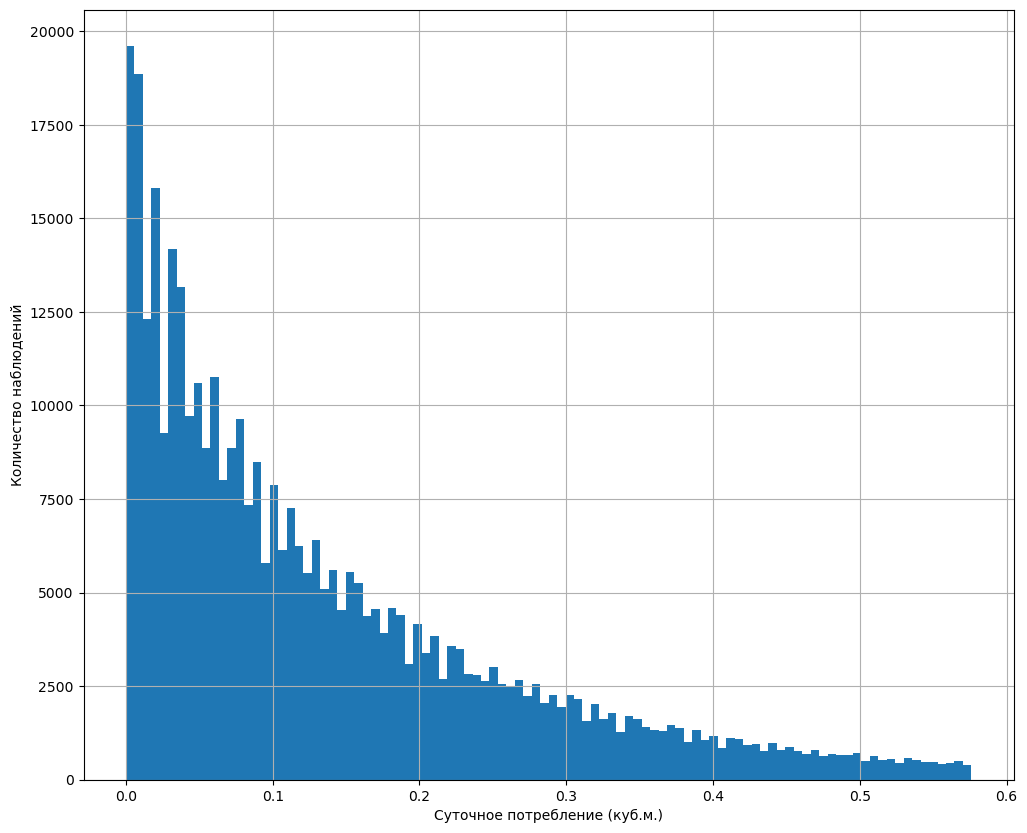

In [258]:
plt.figure(figsize=(12, 10))
plt.hist(typ_potreb.sut_potreb, bins=100)
plt.grid()
plt.xlabel("Суточное потребление (куб.м.)")
plt.ylabel("Количество наблюдений")
plt.show()

После исключения 5% экстремально больших значений по суточным расходам были рассмотрены типичные положительные значения. 95% наблюдений не превышают 0.576 куб.м. в сутки, при этом график показывает, что основная доля наблюдений сосредеточена в диапазоне до 0.5-0.6 куб.м. в сутки. В качестве абсолютного порога всплеска выбрано значение 0.6 куб.м. в сутки. 

<br> Также в качестве дополнительного обоснования была использована статистика о среднем водопотреблении в Астане. На 2025 год на одного человека приходилось 67.8 куб.м. в год (0.186 куб.м. в сутки). Среднестатистическое домохозяйство состоит из 3 человек => 3 * 0.186 = 0.558 куб.м. в сутки. Полученное значение близко к 95% перцентилю выборки, которое составляет 0.576 куб.м. в сутки. Поэтому в качестве абсолютного порога всплеска принято значение 0.6 куб.м. в сутки.
<br> Примеры аномальных ID: 2491162, 8908023, 2159987, 7891133, 8973572

<br> Ссылка на водопотребление в г. Астана: https://www.gov.kz/memleket/entities/water/press/news/details/1242034?lang=ru
<br> Ссылка на количество человек в семье: https://ranking.kz/reviews/socium/odnogo-by-prokormit-v-kazahstane-padayut-pokazateli-rozhdaemosti.html 

In [259]:
potreb_abs = pos_count.sut_potreb > 0.6
anom_abs = pos_count.loc[potreb_abs, :].copy()
unique_id_abs = anom_abs.sort_values("sut_potreb", ascending=False)[["anon_id", "sut_potreb"]]

print(f"Количество случаев: {len(anom_abs)}")
print(f"Количество приборов: {anom_abs.anon_id.nunique()}")
print(f"Примеры аномальных ID: {unique_id_abs.head()}")

Количество случаев: 18536
Количество приборов: 743
Примеры аномальных ID:         anon_id    sut_potreb
442977  2491162  3.005504e+06
455296  8908023  2.684039e+06
397633  2159987  2.834770e+03
266442  7891133  2.124960e+03
282480  8973572  6.081360e+02


In [260]:
print(f"Доля меньше порога 0.1: {(pos_count.sut_potreb < 0.1).mean()}")
print(f"Количество: {(pos_count.sut_potreb < 0.1).sum()}")
print("=============================================")
print(f"Доля меньше порога 0.3: {(pos_count.sut_potreb < 0.3).mean()}")
print(f"Количество: {(pos_count.sut_potreb < 0.3).sum()}")
print("=============================================")
print(f"Доля меньше порога 0.5: {(pos_count.sut_potreb < 0.5).mean()}")
print(f"Количество: {(pos_count.sut_potreb < 0.5).sum()}")
print("=============================================")
print(f"Доля больше порога 0.7: {(pos_count.sut_potreb >= 0.7).mean()}")
print(f"Количество: {(pos_count.sut_potreb >= 0.7).sum()}")
print("=============================================")
print(f"Доля больше порога 1: {(pos_count.sut_potreb >= 1).mean()}")
print(f"Количество: {(pos_count.sut_potreb >= 1).sum()}")
print("=============================================")
print(f"Доля больше порога 3: {(pos_count.sut_potreb >= 3).mean()}")
print(f"Количество: {(pos_count.sut_potreb >= 3).sum()}")
print("=============================================")
print(f"Доля больше порога 5: {(pos_count.sut_potreb >= 5).mean()}")
print(f"Количество: {(pos_count.sut_potreb >= 5).sum()}")
print("=============================================")
print(f"Доля больше порога 10: {(pos_count.sut_potreb >= 10).mean()}")
print(f"Количество: {(pos_count.sut_potreb >= 10).sum()}")

Доля меньше порога 0.1: 0.4858768066001458
Количество: 194582
Доля меньше порога 0.3: 0.8315030114164145
Количество: 332997
Доля меньше порога 0.5: 0.9331320728333283
Количество: 373697
Доля больше порога 0.7: 0.03469121745123303
Количество: 13893
Доля больше порога 1: 0.019277060298245087
Количество: 7720
Доля больше порога 3: 0.0030263985856830372
Количество: 1212
Доля больше порога 5: 0.0016455418052517504
Количество: 659
Доля больше порога 10: 0.0009463738151599596
Количество: 379


In [261]:
# поиск относительного всплеска
med_potreb = pos_count.groupby("anon_id")["sut_potreb"].median() # медианный расход в сутки для каждого прибора
pos_count["med_potreb"] = pos_count.anon_id.map(med_potreb)
pos_count["otn_potreb"] = pos_count.sut_potreb.values / pos_count.med_potreb.values # во сколько раз текущий расход больше медианного
pos_count
pos_count.otn_potreb.quantile([0.90, 0.95, 0.99, 0.995, 0.999]) 

0.900     2.104068
0.950     2.791667
0.990     5.846199
0.995     9.012140
0.999    63.061994
Name: otn_potreb, dtype: float64

In [262]:
anom_del_otn = pos_count.otn_potreb.quantile(0.95)                             # порог всплеска по 95% квантилю
anom_otn = pos_count.loc[pos_count.otn_potreb.values > anom_del_otn, :].copy() # оставляем оставшиеся 5% всплесков
unique_id_otn = anom_otn.sort_values("otn_potreb", ascending=False)[["anon_id", "sut_potreb", "med_potreb","otn_potreb"]]

print(f"Количество случаев: {len(anom_otn)}")
print(f"Количество приборов: {anom_otn.anon_id.nunique()}")
print(f"Примеры аномальных ID: {unique_id_otn.head(10)}")

Количество случаев: 20024
Количество приборов: 1762
Примеры аномальных ID:         anon_id    sut_potreb  med_potreb    otn_potreb
455296  8908023  2.684039e+06      0.0945  2.840253e+07
442977  2491162  3.005504e+06      0.1950  1.541284e+07
156643  8953379  3.276800e+02      0.0100  3.276800e+04
156640  8953379  3.276750e+02      0.0100  3.276750e+04
156647  8953379  3.276750e+02      0.0100  3.276750e+04
156636  8953379  3.276500e+02      0.0100  3.276500e+04
282480  8973572  6.081360e+02      0.0300  2.027120e+04
112068  9435441  3.276700e+02      0.0170  1.927471e+04
112054  9435441  3.276400e+02      0.0170  1.927294e+04
112066  9435441  3.276300e+02      0.0170  1.927235e+04


Относительный всплеск = текущ. сут. потребление / медианное сут. потребление.
<br> У 95% наблюдений относит. потребление не превышает 2.791, поэтому значения выше этого порога были приняты за аномальные всплески. Количество приборов с аномальными относительными всплесками: 1762.
<br> Примеры аномальных ID: 8908023, 8953379, 8973572, 9435441

In [263]:
otn_porog_3 = pos_count.otn_potreb >= 3
otn_porog_6 = pos_count.otn_potreb >= 6
otn_porog_9 = pos_count.otn_potreb >= 9

print(f"Доля больше порога 3: {(otn_porog_3 * 100).mean()}")
print(f"Количество: {(otn_porog_3).sum()}")
print("=============================================")
print(f"Доля меньше порога 6: {(otn_porog_6 * 100).mean()}")
print(f"Количество: {(otn_porog_6).sum()}")
print("=============================================")
print(f"Доля меньше порога 9: {(otn_porog_9 * 100).mean()}")
print(f"Количество: {(otn_porog_9).sum()}")

Доля больше порога 3: 4.157802215363717
Количество: 16651
Доля меньше порога 6: 0.9533654950608775
Количество: 3818
Доля меньше порога 9: 0.5036506557196936
Количество: 2017


# 3. НЕРЕАЛЬНЫЕ значения — физически невозможный расход (десятки и тысячи м³ в сутки). Найдите такие приборы.

In [264]:
pos_count.sut_potreb.sort_values(ascending=False).head(60)

442977    3.005504e+06
455296    2.684039e+06
397633    2.834770e+03
266442    2.124960e+03
282480    6.081360e+02
393009    5.303171e+02
92917     4.259160e+02
457995    4.010470e+02
386043    3.640533e+02
268476    3.639711e+02
92966     3.528254e+02
92935     3.526559e+02
415971    3.432248e+02
415974    3.422944e+02
92938     3.412742e+02
457996    3.347866e+02
252958    3.320580e+02
415978    3.308582e+02
456943    3.281390e+02
163203    3.279960e+02
163174    3.279660e+02
146309    3.279530e+02
418665    3.278760e+02
272058    3.278710e+02
433680    3.278337e+02
387062    3.278110e+02
455290    3.278043e+02
384341    3.278020e+02
411505    3.277970e+02
135669    3.277529e+02
92920     3.276913e+02
384860    3.276810e+02
261266    3.276800e+02
156643    3.276800e+02
171439    3.276790e+02
429583    3.276770e+02
156640    3.276750e+02
156647    3.276750e+02
454084    3.276730e+02
92987     3.276700e+02
135658    3.276700e+02
444446    3.276700e+02
272090    3.276700e+02
261253    3

In [265]:
prib.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   anon_id         3000 non-null   int64 
 1   bs              3000 non-null   object
 2   tip             3000 non-null   object
 3   model           2981 non-null   object
 4   mesyac_vypuska  3000 non-null   object
dtypes: int64(1), object(4)
memory usage: 117.3+ KB


In [266]:
prib.model.value_counts()

model
АКВА L110 D15 C E    1820
АКВА L110 D15 B E    1147
АКВА L130 D20 C E      11
АКВА L130 D20 B E       3
Name: count, dtype: int64

<br> АКВА L110 D15 C E - диаметр прохода 15 мм, максимальный расход 3 куб.м. в час. Счетчик холодной воды.
<br> АКВА L110 D15 B E - диаметр прохода 15 мм, максимальный расход 3 куб.м. в час. Счетчик горячей воды.
<br> Для 15 С и 15 В максимальный объем в сутки 37.5 куб.м.
<br> https://kaspi.kz/shop/p/waviot-akva-l110-d15-se-101429582/srsltid=AU7gw4WAQfeZgIC01ajjMxUSKtXIff7vSLL4nAcOCxyyZdd9rfDTJkQp
<br> ================================================================================================================
<br> АКВА L130 D20 C E - максимальный расход 5 куб.м. в час. 
<br> АКВА L130 D20 B E - - максимальный расход 5 куб.м. в час. 
<br> Для 20 С и 20 В максимальный объем в сутки 62.5 куб.м.
<br> https://grmetr.ru/gosreestr/382400-68350-17-tipa-akva

<br> Метрологические и технические характеристики: https://grmetr.ru/media/pdf/2023-68350-17-1.pdf

In [267]:
pos_count = pos_count.merge(prib[["anon_id", "model"]], on = "anon_id", how = "left")
pos_count 

,anon_id,data,pokazanie,paketov_za_sutki,prev_pok,sut_potreb,prev_data,day_diff,med_potreb,otn_potreb,model
0,1001589,2025-10-02,280.840000,1,280.760000,0.080000,2025-10-01,1.0,0.030,2.666667,АКВА L110 D15 B E
1,1001589,2025-10-03,280.864000,2,280.840000,0.024000,2025-10-02,1.0,0.030,0.800000,АКВА L110 D15 B E
2,1001589,2025-10-04,280.910000,1,280.864000,0.046000,2025-10-03,1.0,0.030,1.533333,АКВА L110 D15 B E
3,1001589,2025-10-05,281.130000,1,280.910000,0.220000,2025-10-04,1.0,0.030,7.333333,АКВА L110 D15 B E
4,1001589,2025-10-06,281.180000,1,281.130000,0.050000,2025-10-05,1.0,0.030,1.666667,АКВА L110 D15 B E
...,...,...,...,...,...,...,...,...,...,...,...
400471,9997690,2026-09-26,725.350000,19,724.443500,0.906500,2026-09-25,1.0,0.284,3.191901,АКВА L110 D15 B E
400472,9997690,2026-09-27,726.116111,25,725.350000,0.766111,2026-09-26,1.0,0.284,2.697574,АКВА L110 D15 B E
400473,9997690,2026-09-28,727.044353,25,726.116111,0.928242,2026-09-27,1.0,0.284,3.268457,АКВА L110 D15 B E
400474,9997690,2026-09-29,727.723727,25,727.044353,0.679374,2026-09-28,1.0,0.284,2.392163,АКВА L110 D15 B E


In [268]:
D15_max = ( ( pos_count.model.str.contains("D15") ) & ( pos_count.sut_potreb.values > 37.5 ) )
D20_max = ( ( pos_count.model.str.contains("D20") ) & ( pos_count.sut_potreb.values > 62.5 ) )

unreal_cond = D15_max | D20_max
unreal_znach = pos_count.loc[unreal_cond, :].copy()

print(f"Количество случаев невозможного расхода: {len(unreal_znach)}")
print(f"Количество уникальных приборов: {unreal_znach.anon_id.nunique()}")
print(f"Примеры аномальных ID: {unreal_znach.anon_id.unique()[:15]}")

unreal_znach.sort_values("sut_potreb", ascending=False)[["anon_id", "sut_potreb", "model"]]

Количество случаев невозможного расхода: 280
Количество уникальных приборов: 52
Примеры аномальных ID: [1023776 1184793 1492831 1698800 2030325 2159987 2351232 2491162 2519659
 2569627 2647530 2665800 2859628 2983464 3281821]


,anon_id,sut_potreb,model
73534,2491162,3.005504e+06,АКВА L110 D15 B E
353370,8908023,2.684039e+06,АКВА L110 D15 B E
57186,2159987,2.834770e+03,АКВА L110 D15 B E
310542,7891133,2.124960e+03,АКВА L110 D15 B E
192715,5359103,5.303171e+02,АКВА L110 D15 B E
...,...,...,...
50005,2030325,4.376205e+01,АКВА L110 D15 B E
338127,8498147,4.104250e+01,АКВА L110 D15 C E
50011,2030325,4.102837e+01,АКВА L110 D15 B E
50000,2030325,4.098886e+01,АКВА L110 D15 B E


Для выявления физически невозможных расходов использовались метрологические и технические характеристики счетчиков моделей D15 и D20 (см. ссылку выше). Согласно технической документации, максимальный суточный расход для счетчиков модели D15 составляет 37.5 куб.м., а для модели D20 - 62.5 куб.м.

<br> Из таблицы pribory к основной анализируемой таблице pos_count была присоединена информация о моделях (model). Далее были отобраны случаи, когда для моделей "D15" суточное потребление превышало 37.5 куб.м., а для "D20" - 62.5 куб.м. Таким образом, у 52 приборов количество нереальных расходов составило 280 случаев.

<br> Примеры ID приборов с невозможными значениями расхода: 1023776, 1184793, 1492831, 1698800, 2030325, 2159987.

# 4. УТЕЧКА — непрерывное потребление без «нулевых» суток длительное время (прибор никогда не «отдыхает»). Ваш критерий и сколько.

In [269]:
# положительное суточное потребление и показания идут каждый день 
pok["utechka_cond"] = (pok.sut_potreb.values > 0) & (pok.day_diff.values == 1)

# поиск приборов, для которых возникали разрывы
# разрывы помечены значением False (не удовлет-ют условию выше)
# считаем количество накопленных разрывов
pok["utechka_razryv"] = (pok.utechka_cond == False).groupby(pok.anon_id).cumsum()

# оставляем положительные расходы
utechka_count = pok.loc[pok.utechka_cond, :].copy()

# разделяем данные на отдельные непрерывные периоды:
# количество строк в utechka_razryv = количеству дней этого периода
utechka_day = utechka_count.groupby(["anon_id", "utechka_razryv"]).size().reset_index(name="days")
utechka_day.head(30)

,anon_id,utechka_razryv,days
0,1001589,1,10
1,1001589,2,1
2,1001589,4,7
3,1001589,5,2
4,1001589,10,1
5,1001589,11,3
6,1001589,12,4
7,1001589,13,1
8,1001589,14,1
9,1001589,16,1


Видно, что у 1 прибора может быть несколько отдельных непрерывных дней

In [270]:
# min суточное потребление для каждого прибора
pos_count_utechka_anom = utechka_count.groupby(["anon_id", "utechka_razryv"])["sut_potreb"].min().values

# id прибора для каждого непрерывного периода
id_utechka_anom = utechka_count.groupby(["anon_id", "utechka_razryv"])["sut_potreb"].min().reset_index()["anon_id"].values

# номер непрерывного периода для каждого прибора
utechka_razryv = utechka_count.groupby(["anon_id", "utechka_razryv"])["sut_potreb"].min().reset_index()["utechka_razryv"].values

# датафрейм: id прибора, min расход, номер периода
pos_count_utechka_anom = pd.DataFrame(data = np.array([id_utechka_anom, pos_count_utechka_anom, utechka_razryv]).T, columns = ["id_utechka_anom", "potreb_count_utechka_anom", "utechka_razryv"]) # новый датафрейм
pos_count_utechka_anom.id_utechka_anom = pos_count_utechka_anom.id_utechka_anom.values.astype(int) # значения id в целочисленный формат
pos_count_utechka_anom.utechka_razryv = pos_count_utechka_anom.utechka_razryv.values.astype(int)
pos_count_utechka_anom

,id_utechka_anom,potreb_count_utechka_anom,utechka_razryv
0,1001589,0.003000,1
1,1001589,0.080000,2
2,1001589,0.040000,4
3,1001589,0.016000,5
4,1001589,0.034000,10
...,...,...,...
51449,9997690,0.379929,20
51450,9997690,0.233500,21
51451,9997690,0.190364,22
51452,9997690,0.386316,23


/var/folders/zx/zdr9bm717_bdfp5hpkt7cxd80000gn/T/ipykernel_1425/1442538260.py:2: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.01`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(x, bw = 0.01)


<Axes: ylabel='Density'>

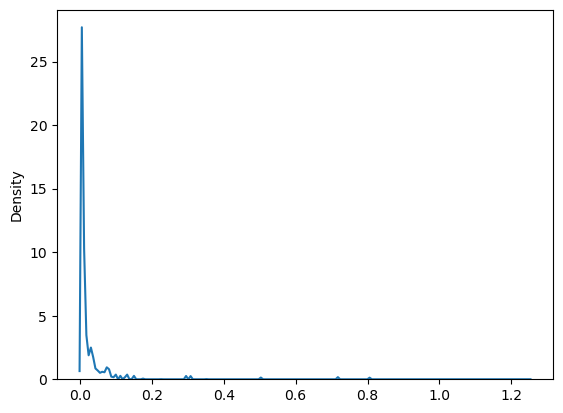

In [271]:
x = pos_count_utechka_anom.groupby("id_utechka_anom")["potreb_count_utechka_anom"].min().values
sns.kdeplot(x, bw = 0.01)

<br> На графике распределения можно заметить, что аномальные значения наблюдается приблизительно после 0.1 куб.м. в сутки. Таким образом, в качестве порогового значения был выбран 0.1 куб.м.

In [272]:
utechka_day = utechka_count.groupby(["anon_id", "utechka_razryv"]).size().reset_index(name="days") # сколько дней подряд длилось непрерывное потребление
utechka_day = utechka_day.rename(columns={"anon_id": "id_utechka_anom"})
pos_count_utechka_anom = pos_count_utechka_anom.merge(utechka_day, on=["id_utechka_anom", "utechka_razryv"]) # объединяем, получаем мин. сут. расход и длительность
pos_count_utechka_anom

,id_utechka_anom,potreb_count_utechka_anom,utechka_razryv,days
0,1001589,0.003000,1,10
1,1001589,0.080000,2,1
2,1001589,0.040000,4,7
3,1001589,0.016000,5,2
4,1001589,0.034000,10,1
...,...,...,...,...
51449,9997690,0.379929,20,4
51450,9997690,0.233500,21,22
51451,9997690,0.190364,22,8
51452,9997690,0.386316,23,1


/var/folders/zx/zdr9bm717_bdfp5hpkt7cxd80000gn/T/ipykernel_1425/1439693501.py:2: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.05`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(x, bw = 0.05)


<Axes: ylabel='Density'>

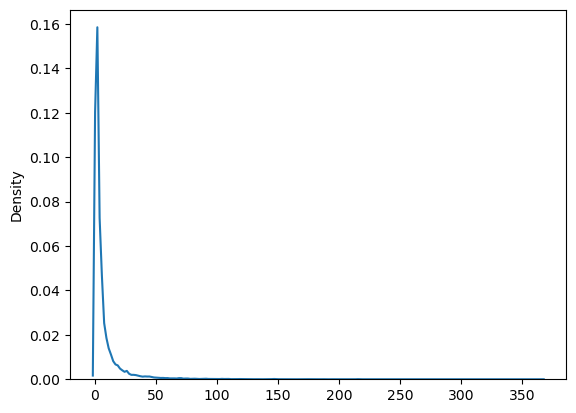

In [273]:
x = utechka_day.days.values    
sns.kdeplot(x, bw = 0.05)

In [274]:
utechka_day.days.describe()

count    51454.000000
mean         7.783185
std         16.752373
min          1.000000
25%          1.000000
50%          3.000000
75%          7.000000
max        365.000000
Name: days, dtype: float64

In [275]:
utechka_day.days.quantile([0.50, 0.75, 0.90, 0.95, 0.99])

0.50     3.0
0.75     7.0
0.90    18.0
0.95    31.0
0.99    79.0
Name: days, dtype: float64

In [333]:
mask_utechka = (pos_count_utechka_anom.potreb_count_utechka_anom > 0.1) & (pos_count_utechka_anom.days > 31)
utechka = pos_count_utechka_anom.loc[mask_utechka, :]
print(f"Количество аномальных приборов (утечка) выше порога: {utechka.id_utechka_anom.nunique()}")
print(f"Примеры аномальных ID: {utechka.id_utechka_anom.unique()[:5]}")

Количество аномальных приборов (утечка) выше порога: 171
Примеры аномальных ID: [1017574 1023776 1068203 1120133 1160330]


Для выявления утечек были взяты непрерывные периоды, в течение которых наблюдались положительные суточные потребления. График распределения минимального суточного расхода показывает, что выше 0.1 куб.м. в хвосте распределения наблюдаются аномальные значения. Также распределение длительности непрерывных периодов показывает, что 95% наблюдений не превышают 31 день. Следовательно, для порога должны одновременно выполняться 2 условия:
<br> 1) минимальный суточный расход > 0.1 куб.м.
<br> 2) непрерывное потребление > 31 дня

# 5. НУЛЕВОЕ потребление длительно, хотя прибор продолжает слать пакеты (пустая квартира / застрявший счётчик). Порог и количество.

Порог - медианное значение колонки null_potreb в датасете null_potreb.
<br> Пороговое (медианное) значение: 0.036 куб.м. Значения, которые меньше медианы (порога) будем считать аномально низкими (почти нулевыми).
<br> Количество аномально низких показаний счетчика: 1499

Всего счетчиков с нулевым потреблением: 2999
Пороговое значение: 0.03632596685082871
Количество счетчиков с аномальными показаниями: 1499


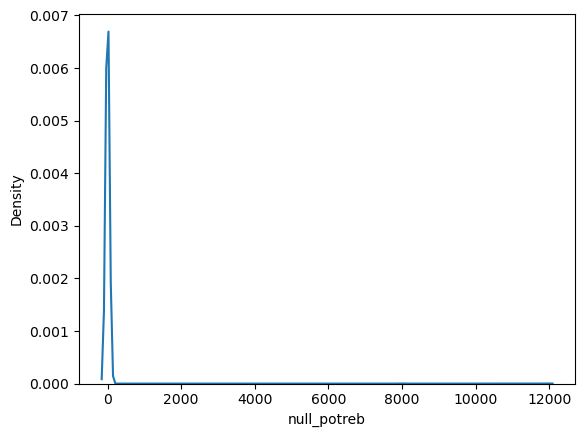

In [279]:
null_potreb = pok_1_day.loc[pok_1_day.sut_potreb >= 0, :].groupby("anon_id")["sut_potreb"].mean().values
id_null_potreb = pok_1_day.loc[pok_1_day.sut_potreb >= 0, :].groupby("anon_id")["sut_potreb"].mean().reset_index()["anon_id"].values
null_potreb = pd.DataFrame(data = np.array([id_null_potreb, null_potreb]).T, columns = ["id_null_potreb", "null_potreb"]) # новый датафрейм
null_potreb.id_null_potreb = null_potreb.id_null_potreb.values.astype(int) # значения id в целочисленный формат

median_ = median( pok_1_day.loc[pok_1_day.sut_potreb >= 0, :].groupby("anon_id")["sut_potreb"].mean().values )
anom_schet = null_potreb.loc[null_potreb.null_potreb < median_, :]

x = null_potreb.null_potreb
sns.kdeplot(x)

print(f"Всего счетчиков с нулевым потреблением: {len(null_potreb)}")
print(f"Пороговое значение: {median_}")
print(f"Количество счетчиков с аномальными показаниями: {len(anom_schet)}")

# 6. СТУПЕНЬКА — резкое устойчивое изменение уровня потребления (например, средний расход во второй половине периода в разы выше первой).

In [329]:
np.unique(pok.anon_id.values )[:10]

array([1001589, 1009827, 1010676, 1013205, 1017147, 1017574, 1018690,
       1023776, 1026548, 1029380])

In [334]:
from scipy.stats import  ttest_ind, ks_2samp

def stupenka( pok, id_, first_data, last_data, t ):
    '''
    pok - датасет, содержащий суточные показания расходов.
    id_ - идентификатор анализируемого прибора.
    first_data - начало анализируемого периода.
    last_data  - конец анализируемого периода.
    t - порог, по которому анализируемый период делится на 2 части.
    
    mask_data_id - маска для отбора данных выбранного прибора за указанный период.
    data - датафрейм с суточным потреблением выбранного прибора за указанный период.
    group1, group2 - первая половина анализируемого периода, вторая половина анализируемого периода.
    statx, px - статистика t-теста для равенства средних 2-х групп, p-значение t-теста.
    stat, pvalue - статистика критерия Колмогорова-Смирнова, p-значение критерия Колмогорова-Смирнова.
    H0 - нулевая гипотеза: отсутствие выбросов и ступенек.
    H1 - альтернативная гипотеза: наличие выбросов или ступеньки.
    '''
    print('===================================================================')
    print(f'  Рассматриваемый период {first_data} - {last_data}')
    print(f'  ID = {id_}')
    
    mask_data_id = ( pok.data > first_data) & ( pok.data  <= last_data ) & (pok.anon_id == id_ )
    data = pok.loc[ mask_data_id ,['sut_potreb']]
    
    group1, group2 = data.values.T[0][:t], data.values.T[0][t:]
    print( group1, group2 )
    
    # тест на равенство средних
    
    print('===================================================================')
    
    print('Статистический тест на равенство 2-х средних')
    
    statx, px = ttest_ind(group1, group2)
    
    print(f"  tx        = {statx:.4f}")
    print(f"  px-value  = {px:.6f}")
    
    if px < 0.05:
        print( "Среднии статистически различаются. Есть либо выбросы, либо ступенька" )
    else:
        print( "Среднии статистически не различаются. Нет ни выбросов, ни ступеньки" )
    
    print('===================================================================')
    
    stat, pvalue = ks_2samp( group1, group2 )
    
    print('Статистический тест Колмогорова-Смирнова')
    print("  KS statistic:", stat)
    print("  p-value:", pvalue)

    if pvalue < 0.05:
        print("Распределения статистически различаются. Есть либо выбросы, либо ступенька")
    else:
        print("Статистически значимого различия нет. Нет ни выбросов, ни ступеньки")
    
    print('===================================================================')
    
#     return data.values.T[0]
# 1001589, 1009827, 1010676, 1013205!!!, 1017147, 1017574, 1018690,
#       1023776, 1026548, 1029380    
stupenka( pok, 1013205, '2026-01-01', '2026-02-28', 30 ) 
# stupenka( pok, 1001589, '2025-11-01', '2025-11-30', 15 )

  Рассматриваемый период 2026-01-01 - 2026-02-28
  ID = 1013205
[0.129 0.193 0.284 0.181 0.155 0.166 0.214 0.103 0.081 0.057 0.051 0.068
 0.101 0.085 0.086 0.02  0.013 0.058 0.106 0.092 0.064 0.076 0.077 0.062
 0.078 0.365 0.109 0.146 0.106 0.102] [0.157 0.136 0.134 0.066 0.117 0.098 0.067 0.051 0.054 0.114 0.079 0.126
 0.025 0.076 0.084 0.148 0.106 0.089 0.073 0.134 0.118 0.068 0.097]
Статистический тест на равенство 2-х средних
  tx        = 1.0601
  px-value  = 0.294114
Среднии статистически не различаются. Нет ни выбросов, ни ступеньки
Статистический тест Колмогорова-Смирнова
  KS statistic: 0.2
  p-value: 0.5877370720978335
Статистически значимого различия нет. Нет ни выбросов, ни ступеньки


# 8. 2–3 собственные находки по потреблению, которые вы заметили.

# 1-ая находка

In [335]:
stupenka( pok, 1013205, '2026-01-01', '2026-02-28', 30 )

  Рассматриваемый период 2026-01-01 - 2026-02-28
  ID = 1013205
[0.129 0.193 0.284 0.181 0.155 0.166 0.214 0.103 0.081 0.057 0.051 0.068
 0.101 0.085 0.086 0.02  0.013 0.058 0.106 0.092 0.064 0.076 0.077 0.062
 0.078 0.365 0.109 0.146 0.106 0.102] [0.157 0.136 0.134 0.066 0.117 0.098 0.067 0.051 0.054 0.114 0.079 0.126
 0.025 0.076 0.084 0.148 0.106 0.089 0.073 0.134 0.118 0.068 0.097]
Статистический тест на равенство 2-х средних
  tx        = 1.0601
  px-value  = 0.294114
Среднии статистически не различаются. Нет ни выбросов, ни ступеньки
Статистический тест Колмогорова-Смирнова
  KS statistic: 0.2
  p-value: 0.5877370720978335
Статистически значимого различия нет. Нет ни выбросов, ни ступеньки


<br> ID = 1013205 
<br> Рассматриваемый период 2026-01-01 - 2026-02-28 статистические тесты за эти 2 зимних месяца не показывают различий в потреблении холодной воды.

In [336]:
stupenka( pok, 1013205, '2026-02-01', '2026-03-31', 28 )

  Рассматриваемый период 2026-02-01 - 2026-03-31
  ID = 1013205
[0.106 0.102 0.157 0.136 0.134 0.066 0.117 0.098 0.067 0.051 0.054 0.114
 0.079 0.126 0.025 0.076 0.084 0.148 0.106 0.089 0.073 0.134 0.118 0.068
 0.097 0.071 0.042 0.035] [0.099 0.079 0.059 0.09  0.072 0.032 0.021 0.041 0.082 0.013 0.065 0.029
 0.098 0.03  0.013 0.072 0.066 0.093 0.059 0.078 0.061 0.074 0.112 0.084
 0.057 0.073 0.072 0.075]
Статистический тест на равенство 2-х средних
  tx        = 3.3396
  px-value  = 0.001526
Среднии статистически различаются. Есть либо выбросы, либо ступенька
Статистический тест Колмогорова-Смирнова
  KS statistic: 0.39285714285714285
  p-value: 0.025624647770069564
Распределения статистически различаются. Есть либо выбросы, либо ступенька


ID = 1013205 
<br> Рассматриваемый период 2026-02-01 - 2026-03-31 статистические тесты за февраль и март показывают различия в потреблении холодной воды. Это означает, что потребление холодной воды в феврале и марте было различным

# 2-ая находка

In [337]:
stupenka( pok, 1013205, '2026-03-01', '2026-11-30', 145 )

  Рассматриваемый период 2026-03-01 - 2026-11-30
  ID = 1013205
[0.042      0.035      0.099      0.079      0.059      0.09
 0.072      0.032      0.021      0.041      0.082      0.013
 0.065      0.029      0.098      0.03       0.013      0.072
 0.066      0.093      0.059      0.078      0.061      0.074
 0.112      0.084      0.057      0.073      0.072      0.075
 0.056      0.059      0.081      0.092      0.013      0.02
 0.085      0.05       0.079      0.102      0.038      0.095
 0.079      0.037      0.037      0.044      0.096      0.099
 0.099      0.051      0.104      0.117      0.072      0.068
 0.013      0.031      0.056      0.066      0.06       0.062
 0.083      0.064      0.104      0.1        0.089      0.076
 0.137      0.075      0.05       0.013      0.068      0.107
 0.081      0.086      0.066      0.069      0.013      0.045
 0.078      0.071      0.102      0.081      0.067      0.016
 0.02       0.114      0.112      0.1        0.049      0.11
 0.084   

ID = 1013205 
<br> Рассматриваемый период 2026-03-01 - 2026-11-30 статистические тесты за весну, лети и осень не показывают различий в потреблении холодной воды

In [32]:
sob

,anon_id,data,sobytie
0,6478032,2026-09-29,магнит
1,6478032,2026-09-29,магнит
2,6478032,2026-09-28,магнит
3,6478032,2026-09-28,магнит
4,6478032,2026-09-28,магнит
...,...,...,...
34004,5417554,2026-03-07,магнит
34005,5417554,2026-03-06,магнит
34006,6190328,2026-05-22,магнит
34007,6190328,2026-05-08,магнит


In [33]:
sob.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34009 entries, 0 to 34008
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   anon_id  34009 non-null  int64 
 1   data     34009 non-null  object
 2   sobytie  34009 non-null  object
dtypes: int64(1), object(2)
memory usage: 797.2+ KB
